# Simple Linear Regression

This notebook implements **simple linear regression** without using Scikit-learn's `LinearRegression` estimator.

We use:
- **NumPy** for numerical calculations,
- **Matplotlib** for visualization,
- Scikit-learn only to generate a sample dataset and split it into training and test sets.

## Learning objectives
By the end of this notebook, you should be able to:
1. Calculate the slope and intercept using the least-squares formulas.
2. Generate predictions using the learned parameters.
3. Calculate Mean Squared Error (MSE).
4. Visualize the fitted regression line.


## 1. Mathematical Formulation

For one input feature, the simple linear regression model is:

$$
\hat{y}_i = ax_i + b
$$

The slope ($a$) and intercept ($b$) are calculated using the training data.

First, we calculate the mean of the input and target values:

$$
\bar{x} = \frac{1}{n}\sum_{i=1}^{n}x_i
\qquad
\bar{y} = \frac{1}{n}\sum_{i=1}^{n}y_i
$$

The slope is calculated as:

$$
a =
\frac{
\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})
}{
\sum_{i=1}^{n}(x_i-\bar{x})^2
}
$$

The intercept is:

$$
b = \bar{y} - a\bar{x}
$$

For evaluating the model on $m$ test observations, we use the Mean Squared Error (MSE):

$$
MSE = \frac{1}{m}\sum_{i=1}^{m}(y_i-\hat{y}_i)^2
$$

**Where:**

- $n$: Number of training observations.
- $m$: Number of test observations.
- $x_i$: Input feature of observation $i$.
- $y_i$: Actual target value.
- $\hat{y}_i$: Predicted target value.
- $a$: Slope (regression coefficient).
- $b$: Intercept.

## 2. Import the required libraries

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression


## 3. Generate the dataset and split it

In [38]:
# Generate a one-feature regression dataset
X, y = make_regression(n_samples=100,n_features=1,random_state=1,noise=5)

# Split the dataset into training (80%) and test (20%) 
n,d = X.shape
n, = y.shape

# Train-Split
X_train = X[0:80]
y_train = y[0:80]

# Test-Split
X_test  = X[80:]
y_test  = y[80:]

print("Training data:", X_train.shape, y_train.shape)
print("Test data:", X_test.shape, y_test.shape)


Training data: (80, 1) (80,)
Test data: (20, 1) (20,)


## 4. Calculate the slope and intercept manually

The following implementation uses the formulas above and a loop. It does **not** use `LinearRegression`, `np.polyfit`, or another regression estimator.

Because this is simple linear regression, we use the first (and only) feature in each row of `X_train`.


In [39]:
# Calculate the means of the training data
x_mean = np.mean(X_train)
y_mean = np.mean(y_train)

# Calculate the numerator and denominator
Up = 0
Dw = 0

n = len(y_train)

for i in range(n):
    Up += (X_train[i] - x_mean) * (y_train[i] - y_mean)
    Dw += (X_train[i] - x_mean) ** 2

# Calculate slope and intercept

slope = Up / Dw
intercept = y_mean - slope * x_mean

print("Slope:", slope)
print("Intercept:", intercept)


Slope: [80.74517]
Intercept: [1.06662889]


## 5. Predict the target values for the test set

In [40]:
# predictions 
y_pred = slope * X_test + intercept

print("First five predictions:", y_pred[:5])
print("First five actual values:", y_test[:5])


First five predictions: [[  73.86572489]
 [-165.27978292]
 [  19.99456426]
 [ -12.85611604]
 [  10.90310812]]
First five actual values: [  85.07599705 -170.17056181   15.05834065  -16.18261323   18.67026285]


## 6. Evaluate the model using MSE

We calculate MSE manually. Notice that the sum of squared errors must be divided by the number of test observations.


In [41]:
MSE = 0
m = len(y_test)

for i in range(m):
    MSE += (y_test[i] - y_pred[i]) ** 2
MSE = MSE / m

print("MSE:", MSE)


MSE: [30.44114532]


## 7. Visualize the training data and regression line

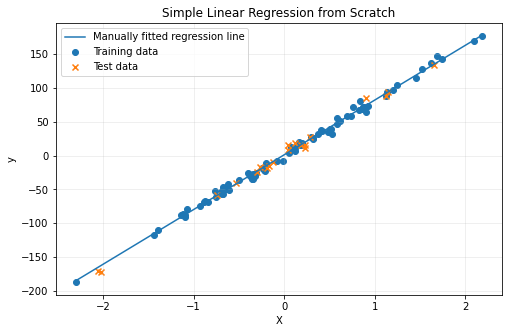

In [59]:
# Create x-coordinates for a smooth regression line
x_line = np.linspace(X_train[:].min(), X_train[:].max(), 100)
y_line = slope * x_line + intercept

plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, label="Training data")
plt.scatter(X_test, y_test, label="Test data", marker="x")
plt.plot(x_line, y_line, label="Manually fitted regression line")
plt.xlabel("X")
plt.ylabel("y")
plt.title("Simple Linear Regression from Scratch")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


In [43]:
# Using the Sklearn Library

In [53]:
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

In [79]:
# 1.Dataset
X,Y = make_regression(n_samples=100,n_features=1,random_state=1,noise=5)

In [80]:
# 2.Train and Test Split function
Xtr,Xte,Ytr,Yte=train_test_split(X,Y,random_state=1,test_size=0.2)

In [81]:
# 3.Train model:Regression 
model = LinearRegression()
model.fit(Xtr,Ytr)
print("slop",model.coef_)
print("intercept",model.intercept_)

slop [81.02679246]
intercept 1.0705721207901524


In [82]:
# 4.Evatution the model
Ypred = model.predict(Xte)
MSE = mean_squared_error(Yte,Ypred)

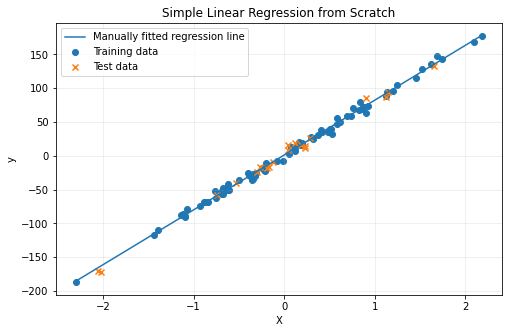

In [83]:
# Create x-coordinates for a smooth regression line
x_line = np.linspace(X_train.min(), X_train.max(), 100)
y_line = model.coef_ * x_line + model.intercept_

plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, label="Training data")
plt.scatter(X_test, y_test, label="Test data", marker="x")
plt.plot(x_line, y_line, label="Manually fitted regression line")
plt.xlabel("X")
plt.ylabel("y")
plt.title("Simple Linear Regression from Scratch")
plt.legend()
plt.grid(alpha=0.25)
plt.show()
